# The Problem Statement
The real estate market in Melbourne is complex and influenced by numerous factors such as property type, number of rooms, land size, location, and year built. Predicting housing prices accurately is valuable for buyers, sellers, and real estate agencies. However, the dataset contains challenges such as missing values, outliers, and categorical features with high cardinality (e.g., suburbs).

The goal of this project is to develop and evaluate machine learning models to predict the price of houses in Melbourne based on property and location features. By implementing a full machine learning lifecycle including data understanding, preprocessing, feature engineering, model selection, evaluation, and reflection we aim to identify the strengths and weaknesses of different approaches.

**Overview of Dataset Columns**

| **Column**        | **Description**                                                        |
|:------------------|:-----------------------------------------------------------------------|
| **Suburb**        | Name of the suburb where the property is located.                      |
| **Address**       | Street address of the property.                                        |
| **Rooms**         | Total number of rooms (bedrooms + living areas).                       |
| **Type**          | Type of dwelling `h` (house), `u` (unit/apartment), `t` (townhouse).   |
| **Price**         | Sale price in Australian dollars (target variable).                    |
| **Method**        | Sale method `S` (sold), `PI` (passed in), `SP` (sold prior), etc.      |
| **SellerG**       | Real estate agent or selling company.                                  |
| **Date**          | Date of sale.                                                          |
| **Distance**      | Distance from the Melbourne CBD (in km).                               |
| **Postcode**      | Postal code of the suburb.                                             |
| **Bedroom**       | Number of bedrooms.                                                    |
| **Bathroom**      | Number of bathrooms.                                                   |
| **Car**           | Number of car spaces.                                                  |
| **Landsize**      | Size of the land in square meters.                                     |
| **BuildingArea**  | Floor area of the building in square meters.                           |
| **YearBuilt**     | Year the property was built.                                           |
| **CouncilArea**   | Local government council area.                                         |
| **Regionname**    | Broad region within Greater Melbourne (e.g., *Southern Metropolitan*). |
| **Propertycount** | Number of properties sold in the suburb (a proxy for local density).   |
| **Latitude**      | Geographic latitude of the property.                                   |
| **Longitude**     | Geographic longitude of the property.                                  |



> **Key findings**
> - Worked on a random sample of **5,000** of the 34,857 listings (seed 42); rows without a sale price were dropped, leaving **3,895** sales (Feb 2016 – Mar 2018).
> - Missing data is heavy: `BuildingArea` 60%, `YearBuilt` 55%, `Landsize` 34%, coordinates 22%. Filled with medians (per property type for `BuildingArea`/`YearBuilt`), modes, and the mean for coordinates.
> - `Price` is strongly right-skewed (skewness 2.42 → 0.33 after a log transform), so models are trained on **log price**.


IMPORT REQUIRED LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import f_oneway, chi2_contingency

In [2]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

Read CSV file and check the first 5 rows


In [3]:
# Before loading the dataset, we inspected the original csv file to check the data structure. We noticed the Column BuildingArea had entries like inf and missing. To handle this we convert these entries upon loading to NAN to facilitate analysis
df = pd.read_csv('../data/raw/melbourne_housing_raw.csv', converters={'BuildingArea': lambda x: np.nan if x in ['missing', 'inf', ''] else float(x)})
df.head()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Abbotsford,68 Studley St,2,h,SS,Jellis,3/9/2016,2.5,3067.0,2.0,...,126.0,NaN,NaN,Yarra City Council,-37.8014,144.9958,Northern Metropolitan,4019.0,Carport,NaN
1,Airport West,154 Halsey Rd,3,t,PI,Nelson,3/9/2016,13.5,3042.0,3.0,...,303.0,225.0,2016.0,Moonee Valley City Council,-37.7180,144.8780,Western Metropolitan,3464.0,Detached Garage,840000.0
2,Albert Park,105 Kerferd Rd,2,h,S,hockingstuart,3/9/2016,3.3,3206.0,2.0,...,120.0,82.0,1900.0,Port Phillip City Council,-37.8459,144.9555,Southern Metropolitan,3280.0,Attached Garage,1275000.0
3,Albert Park,85 Richardson St,2,h,S,Thomson,3/9/2016,3.3,3206.0,2.0,...,159.0,NaN,NaN,Port Phillip City Council,-37.8450,144.9538,Southern Metropolitan,3280.0,Indoor,1455000.0
4,Alphington,30 Austin St,3,h,SN,McGrath,3/9/2016,6.4,3078.0,3.0,...,174.0,122.0,2003.0,Darebin City Council,-37.7818,145.0198,Northern Metropolitan,2211.0,Parkade,NaN


Reducing the dataset to 5000 because the dataset is very large

In [4]:
sample_df = df.sample(n=5000, random_state=42)
print(sample_df.shape)

(5000, 22)


# Basic Info

In [5]:
print(f"\nDataset Shape: {sample_df.shape}")
print(f"\nColumn Names and Types:\n{sample_df.dtypes}")


Dataset Shape: (5000, 22)

Column Names and Types:
Suburb               str
Address              str
Rooms              int64
Type                 str
Method               str
SellerG              str
Date                 str
Distance         float64
Postcode         float64
Bedroom          float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea          str
Latitude         float64
Longtitude       float64
Regionname           str
Propertycount    float64
ParkingArea          str
Price            float64
dtype: object


In [6]:
print("First five rows")
sample_df.head()

First five rows


,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
10953,Northcote,303/231 St Georges Rd,2,u,S,McGrath,12/8/2017,5.3,3070.0,NaN,...,NaN,NaN,NaN,Darebin City Council,NaN,NaN,Northern Metropolitan,11364.0,Detached Garage,673000.0
29454,Bentleigh East,63 Barrington St,3,h,S,Jellis,26/08/2017,13.8,3165.0,3.0,...,NaN,NaN,NaN,Glen Eira City Council,-37.91297,145.07350,Southern Metropolitan,10969.0,Attached Garage,1372500.0
21866,Maribyrnong,3/50 Middle Rd,1,u,PI,Brad,19/08/2017,4.3,3032.0,1.0,...,NaN,33.0,1970.0,Maribyrnong City Council,-37.76722,144.88987,Western Metropolitan,4918.0,Underground,NaN
5673,Reservoir,39 Crevelli St,3,h,S,Stockdale,3/9/2017,12.0,3073.0,3.0,...,170.0,128.0,1950.0,Darebin City Council,-37.72924,145.02981,Northern Metropolitan,21650.0,Outdoor Stall,612500.0
22924,Jacana,53 Lorraine Cr,3,h,S,YPA,20/05/2017,14.5,3047.0,NaN,...,NaN,NaN,NaN,Hume City Council,NaN,NaN,Northern Metropolitan,851.0,Attached Garage,515000.0


In [7]:
sample_df.describe()

,Rooms,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Latitude,Longtitude,Propertycount,Price
count,5000.000000,5000.000000,5000.000000,3844.000000,3843.000000,3767.000000,3308.000000,1999.000000,2256.000000,3879.000000,3879.000000,5000.000000,3.895000e+03
mean,3.014200,11.078200,3113.478200,3.059834,1.594588,1.715954,548.218259,154.545348,1964.761525,-37.809071,144.998170,7688.005200,1.042889e+06
std,0.960303,6.729244,104.388477,0.945323,0.699216,0.975547,1235.013060,111.233053,36.642818,0.090983,0.118023,4419.683293,6.357164e+05
min,1.000000,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1820.000000,-38.182550,144.490000,249.000000,8.500000e+04
25%,2.000000,6.400000,3046.000000,2.000000,1.000000,1.000000,223.750000,101.000000,1940.000000,-37.862100,144.928440,4442.000000,6.300000e+05
50%,3.000000,10.200000,3101.000000,3.000000,1.000000,2.000000,517.000000,135.000000,1970.000000,-37.806720,145.003800,6795.000000,8.600000e+05
75%,4.000000,13.900000,3151.000000,4.000000,2.000000,2.000000,661.000000,182.000000,1998.250000,-37.752680,145.067255,10412.000000,1.280000e+06
max,9.000000,47.400000,3977.000000,8.000000,7.000000,8.000000,41400.000000,3112.000000,2017.000000,-37.397800,145.412880,21650.000000,7.000000e+06


# Missing Values Analysis
1. Check missing values
2. Get the percentage of our dataset that where missing to get better insight of the data

In [8]:
# Count missing values
missing_count = sample_df.isnull().sum()
# how many total missing values do we have?
total_cells = np.prod(sample_df.shape)
total_missing = missing_count.sum()
# Percentage missing
missing_percent = (missing_count / len(sample_df)) * 100

# Create a summary dataframe
missing_summary = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percent': missing_percent
}).sort_values('Missing_Count', ascending=False)
print(missing_summary)

               Missing_Count  Missing_Percent
BuildingArea            3001            60.02
YearBuilt               2744            54.88
Landsize                1692            33.84
Car                     1233            24.66
Bathroom                1157            23.14
Bedroom                 1156            23.12
Latitude                1121            22.42
Longtitude              1121            22.42
Price                   1105            22.10
Method                     0             0.00
Address                    0             0.00
Suburb                     0             0.00
Type                       0             0.00
Rooms                      0             0.00
SellerG                    0             0.00
Distance                   0             0.00
Postcode                   0             0.00
Date                       0             0.00
CouncilArea                0             0.00
Regionname                 0             0.00
Propertycount              0      

In [9]:
# Recommend action based on missing %
def recommend_action(missing_percent, feature):
    if missing_percent == 0:
        return 'Keep as-is'
    elif missing_percent < 1:
        return 'Drop row or fill with mode/median'
    elif missing_percent < 20:
        return 'Impute with median or predictive model'
    else:
        return 'Consider impute with median + missing flag or drop if not critical'

missing_summary['Recommended_Action'] = missing_summary['Missing_Percent'].apply(lambda x: recommend_action(x, x))

# Sort by missing %
missing_df = missing_summary.sort_values(by='Missing_Percent', ascending=False)

# Display
missing_df

,Missing_Count,Missing_Percent,Recommended_Action
BuildingArea,3001,60.02,Consider impute with median + missing flag or ...
YearBuilt,2744,54.88,Consider impute with median + missing flag or ...
Landsize,1692,33.84,Consider impute with median + missing flag or ...
Car,1233,24.66,Consider impute with median + missing flag or ...
Bathroom,1157,23.14,Consider impute with median + missing flag or ...
Bedroom,1156,23.12,Consider impute with median + missing flag or ...
Latitude,1121,22.42,Consider impute with median + missing flag or ...
Longtitude,1121,22.42,Consider impute with median + missing flag or ...
Price,1105,22.10,Consider impute with median + missing flag or ...
Method,0,0.00,Keep as-is


# DATA CLEANING
### Handling missing values:
Replace missing values with mean or median of the column
- For numerical data
- Median preferable if data distribution is skewed

Replace with the mode
- For categorical data
1. Drop rows where 'Price' is missing, since this is the target variable and imputing it could introduce bias in the model.
2. For numerical features that are often skewed (Bedroom, Bathroom, Car, Landsize), replace missing values with the median, which is more robust to outliers.
3. For geographical features (Latitude, Longtitude), replace missing values with the mean, since these variables are not strongly skewed and the mean better preserves location trends.


In [10]:
# 1. Drop rows where Price is missing (target variable) because imputing would bias the model
sample_df = sample_df.dropna(subset=['Price'])

numerical_cols = ["Landsize","Car","Bathroom","Bedroom","ParkingArea"]
for col in numerical_cols:
    if sample_df[col].isnull().sum() > 0:
        sample_df.fillna({col: sample_df[col].median()}, inplace=True)
        print(f"Filled missing values in '{col}' with median")

# For categorical columns, fill with mode
categorical_cols = sample_df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if sample_df[col].isnull().sum() > 0:
        sample_df.fillna({col: sample_df[col].mode()[0]}, inplace=True)
        print(f"Filled missing values in '{col}' with mode")
        
# For geographical columns, fill with mean
geographical_cols = ["Latitude","Longtitude"]
for col in geographical_cols:
    if sample_df[col].isnull().sum() > 0:
         sample_df.fillna({col: sample_df[col].mean()}, inplace=True)
         print(f"Filled missing values in '{col}' with mean")

# Impute BuildingArea and YearBuilt using grouped median per Type
for col in ["BuildingArea", "YearBuilt"]:
    if sample_df[col].isnull().sum() > 0:
        sample_df[col] = sample_df.groupby("Type")[col].transform(
            lambda x: x.fillna(x.median())
        )
        print(f"Filled missing values in '{col}' with median per Type")


Filled missing values in 'Landsize' with median
Filled missing values in 'Car' with median
Filled missing values in 'Bathroom' with median
Filled missing values in 'Bedroom' with median
Filled missing values in 'Latitude' with mean
Filled missing values in 'Longtitude' with mean
Filled missing values in 'BuildingArea' with median per Type
Filled missing values in 'YearBuilt' with median per Type


C:\Users\PC\AppData\Local\Temp\ipykernel_10444\1625625908.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = sample_df.select_dtypes(include=['object']).columns


In [11]:
# checking if the nulls are remove
sample_df.isnull().sum()

Suburb           0
Address          0
Rooms            0
Type             0
Method           0
SellerG          0
Date             0
Distance         0
Postcode         0
Bedroom          0
Bathroom         0
Car              0
Landsize         0
BuildingArea     0
YearBuilt        0
CouncilArea      0
Latitude         0
Longtitude       0
Regionname       0
Propertycount    0
ParkingArea      0
Price            0
dtype: int64

In [12]:
cleaned_df = sample_df
cleaned_df.to_csv('../data/processed/melbourne_housing_cleaned_v1.csv', index=False)

# EXPLORATORY DATA ANALYSIS (EDA) 
### A. Numeric Variable Analysis
Tasks:
- Outlier Detection
- Feature Distribution
- Correlation Analysis


In [13]:
# 1. OUTLIER DETECTION
# List numeric columns
numeric_cols = sample_df.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_cols)

for col in numeric_cols:
    Q1 = sample_df[col].quantile(0.25)
    Q3 = sample_df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = sample_df[(sample_df[col] < lower_bound) | (sample_df[col] > upper_bound)]
    print(f"\n{col} has {len(outliers)} outliers")
    
    # Optional: handle extreme skewed variables
    if sample_df[col].skew() > 1 or sample_df[col].skew() < -1:
        print(f"Consider log-transform or capping for {col}")

Numeric columns: ['Rooms', 'Distance', 'Postcode', 'Bedroom', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'Latitude', 'Longtitude', 'Propertycount', 'Price']

Rooms has 3 outliers

Distance has 166 outliers
Consider log-transform or capping for Distance

Postcode has 107 outliers
Consider log-transform or capping for Postcode

Bedroom has 1597 outliers



Bathroom has 29 outliers
Consider log-transform or capping for Bathroom

Car has 170 outliers
Consider log-transform or capping for Car

Landsize has 137 outliers
Consider log-transform or capping for Landsize

BuildingArea has 256 outliers
Consider log-transform or capping for BuildingArea

YearBuilt has 1055 outliers

Latitude has 250 outliers



Longtitude has 277 outliers

Propertycount has 89 outliers

Price has 179 outliers
Consider log-transform or capping for Price


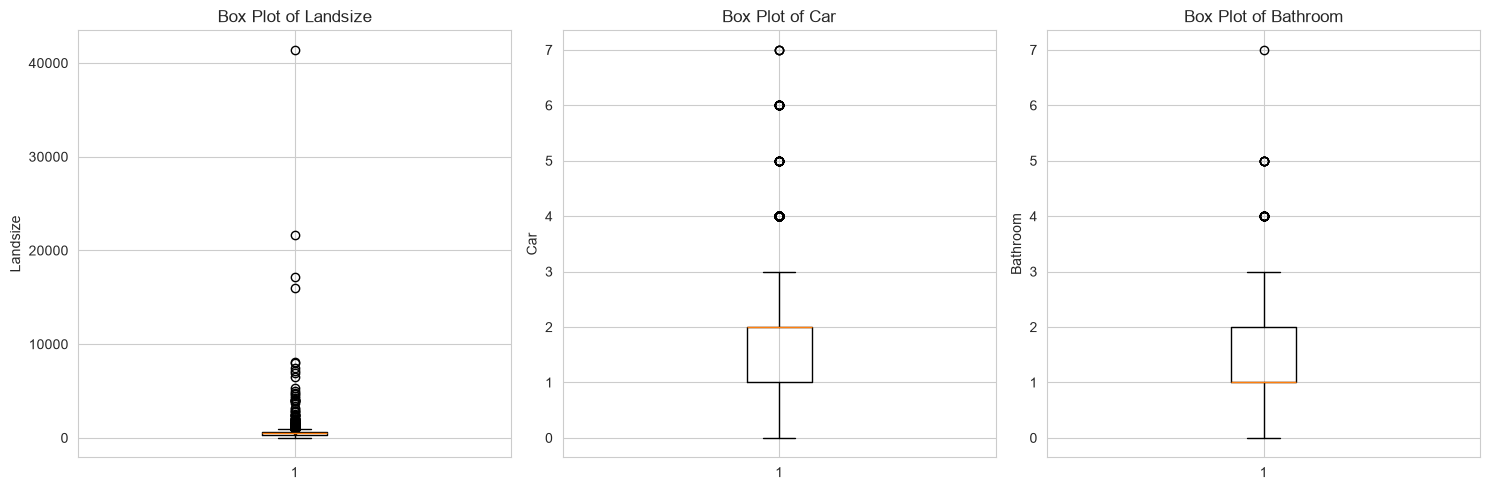

In [14]:
# Box plots for outlier visualization
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for idx, col in enumerate(numerical_cols[:3]):
    axes[idx].boxplot(sample_df[col])
    axes[idx].set_title(f'Box Plot of {col}')
    axes[idx].set_ylabel(col)
plt.tight_layout()
plt.show()

Distribution of numerical columns

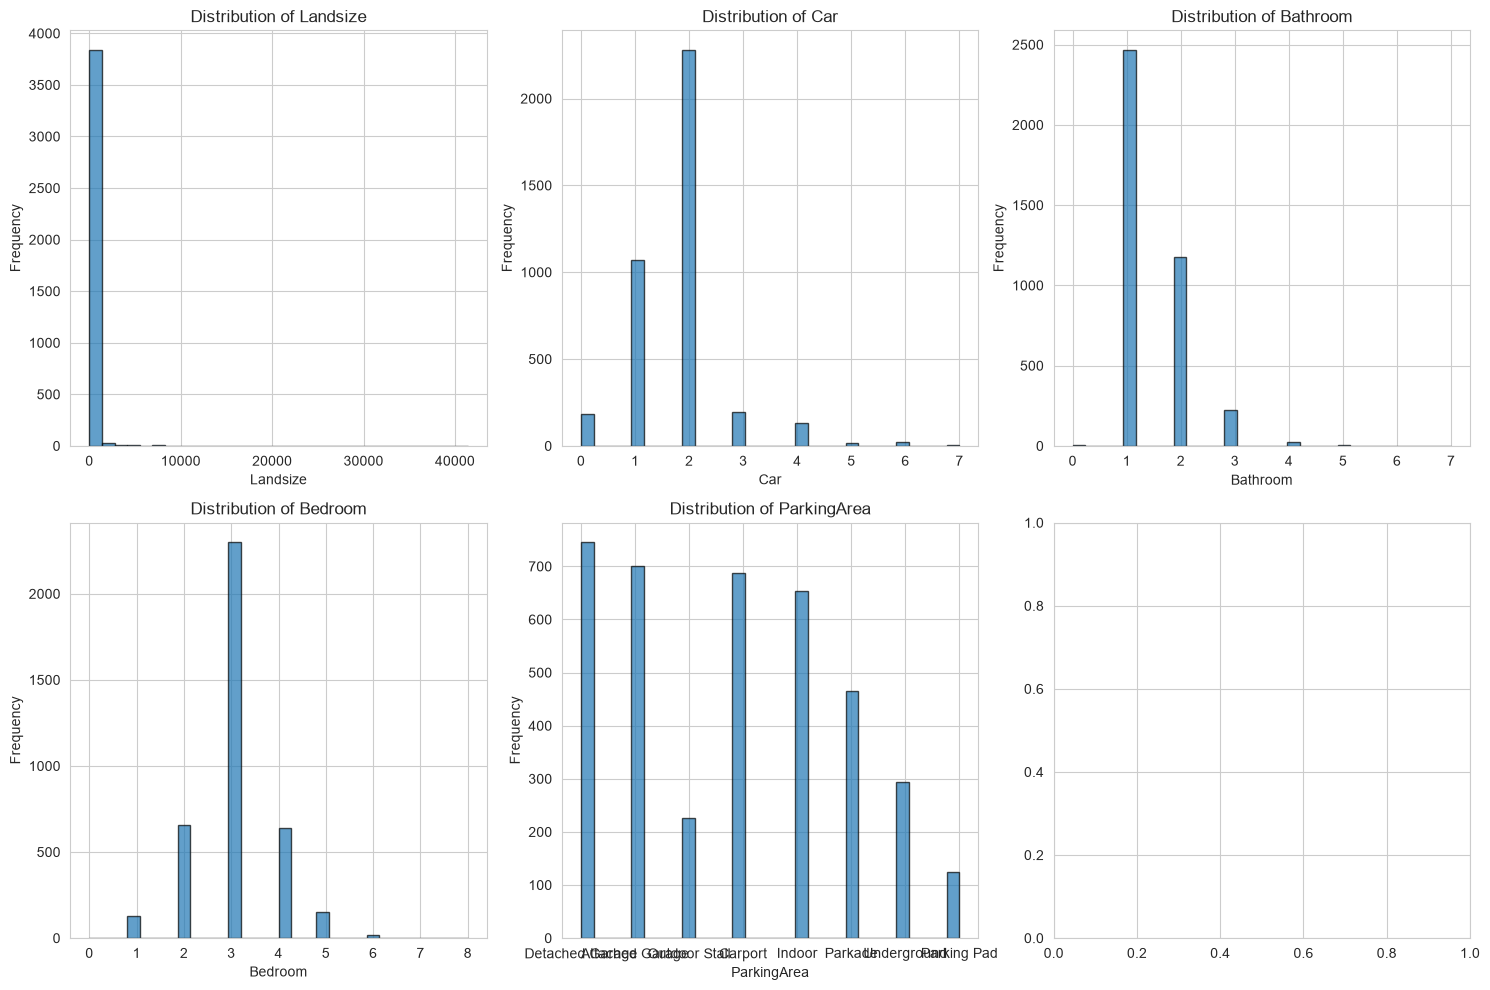

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for idx, col in enumerate(numerical_cols[:5]):
    axes[idx].hist(sample_df[col], bins=30, edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'Distribution of {col}')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Frequency')
plt.tight_layout()
plt.show()

In [16]:
# Check the skewness of each feature
for col in sample_df.select_dtypes(include=[np.number]).columns:
    print(f"\n{col}: {sample_df[col].skew()}")


Rooms: 0.2954773557110986

Distance: 1.4606872525314594

Postcode: 3.9337170269198207

Bedroom: 0.2977060198978905

Bathroom: 1.537199401597647

Car: 1.1112658398839335

Landsize: 27.881094201853983

BuildingArea: 16.38766352640563

YearBuilt: -0.5342910853203242

Latitude: -0.2850205077591587

Longtitude: -0.3569912454791271

Propertycount: 0.9158448946698242

Price: 2.416740465803807


> (-0.5, 0.5) low or approximately symmetric.
> (-1, -0.5) U (0.5, 1) moderately skewed.
> Beyond -1 and 1 Highly skewed.

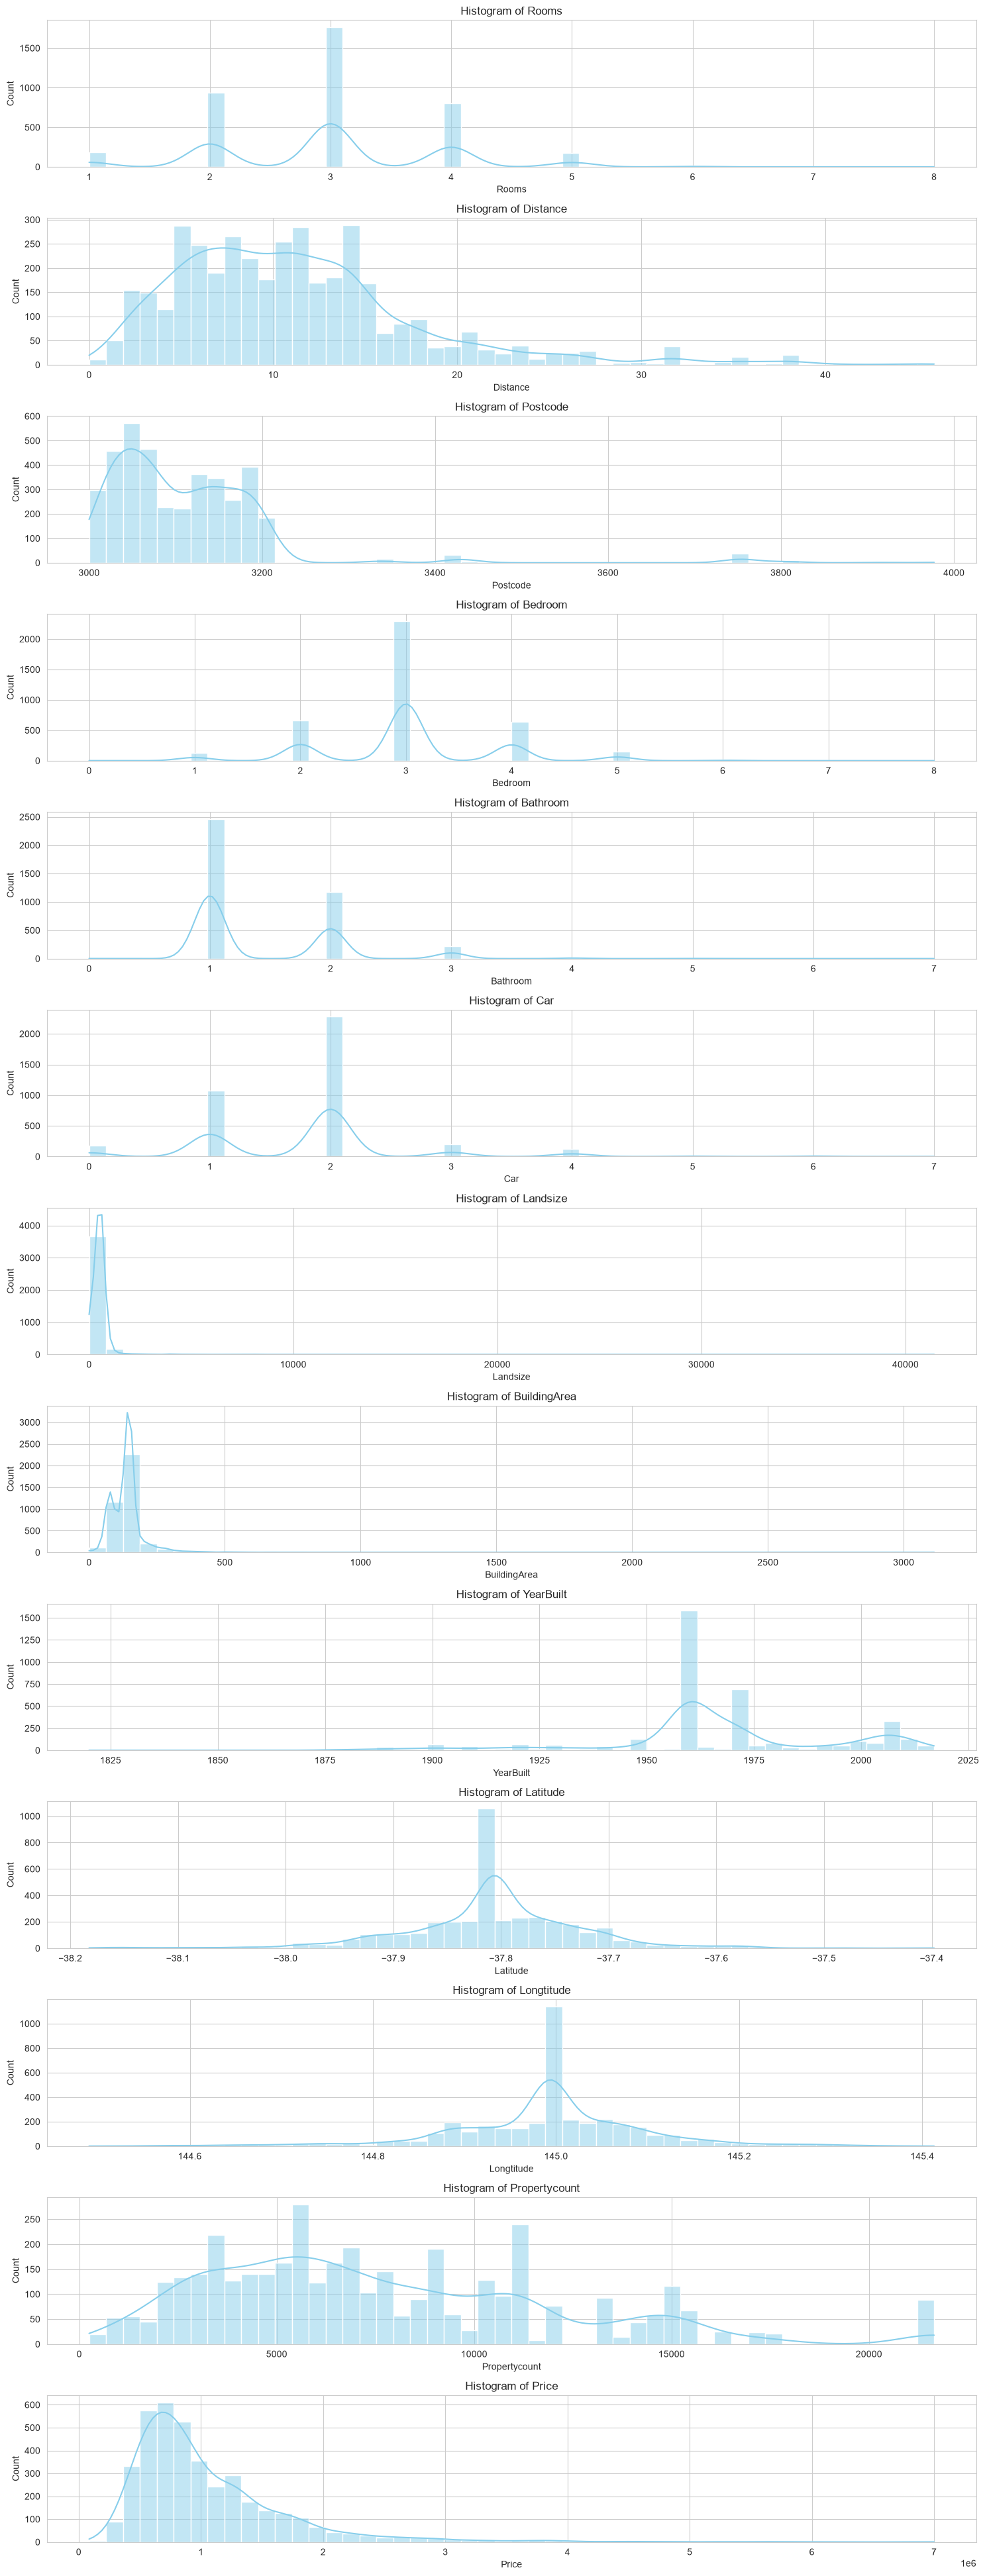

In [17]:
# Plot histogram to visualise skewness for each numeric variable
# -----------------------------
plt.figure(figsize=(15, len(numeric_cols)*3))

for i, col in enumerate(numeric_cols):
    plt.subplot(len(numeric_cols), 1, i+1)
    sns.histplot(sample_df[col], bins=50, kde=True, color='skyblue')
    plt.title(f'Histogram of {col}')
plt.tight_layout()
plt.show()


In [18]:
# Log-transform highly skewed numeric columns
for col in numeric_cols:
   if sample_df[col].skew() > 1 or sample_df[col].skew() < -1:
       sample_df[f'Log_{col}'] = np.log1p(sample_df[col]) # log1p handles zeros

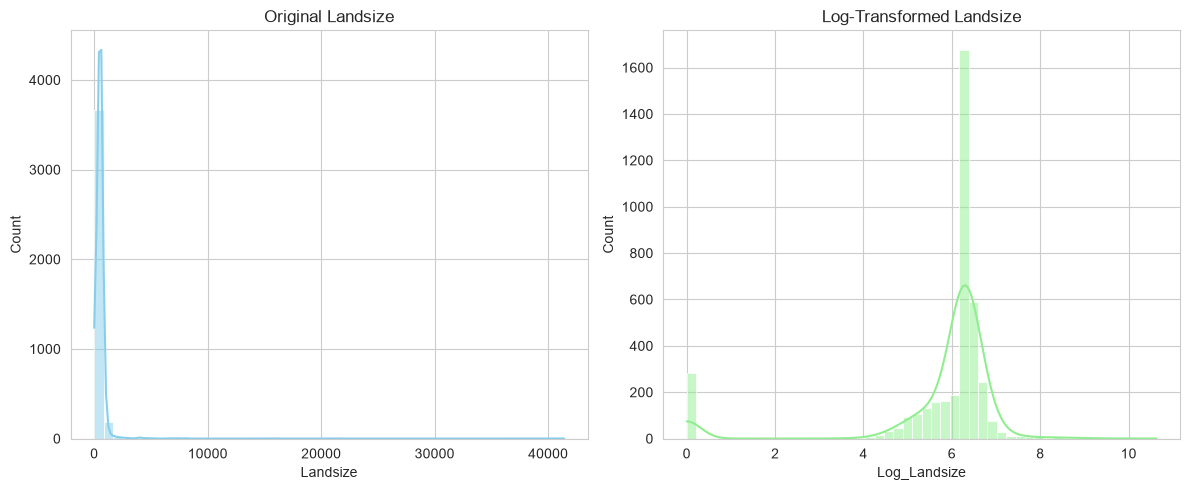

Landsize -> Skewness before: 27.88, after log-transform: -2.75



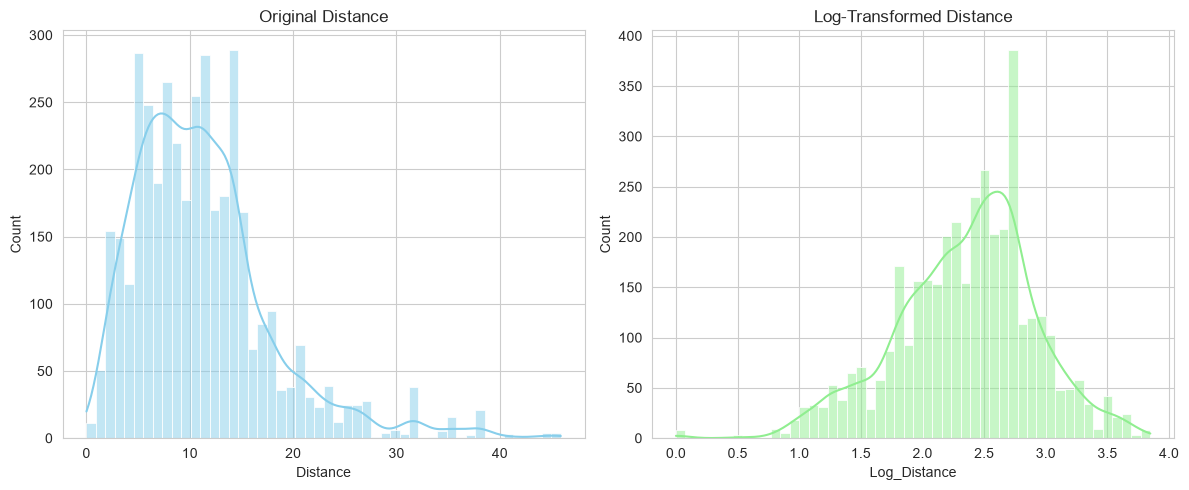

Distance -> Skewness before: 1.46, after log-transform: -0.38



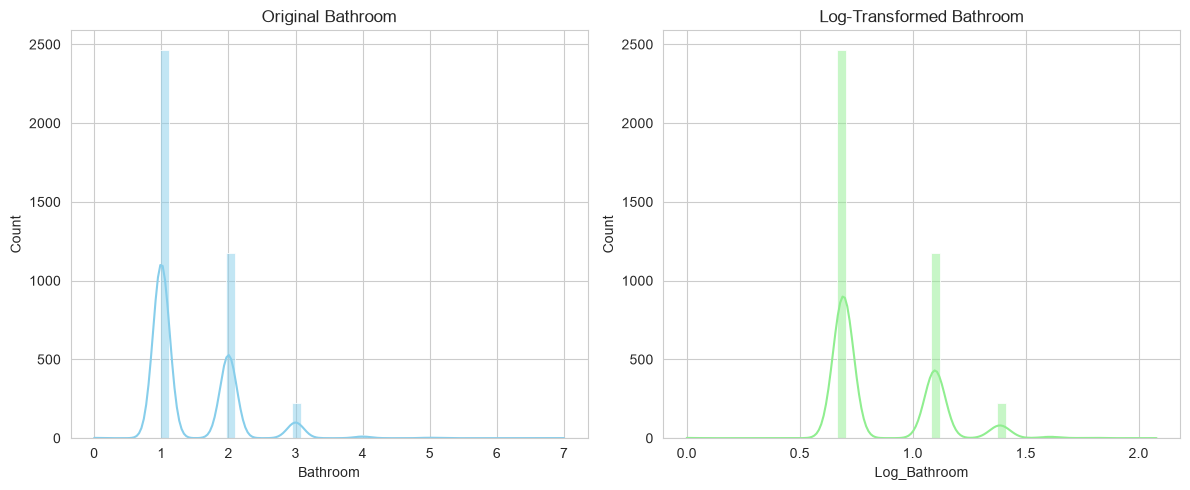

Bathroom -> Skewness before: 1.54, after log-transform: 0.95



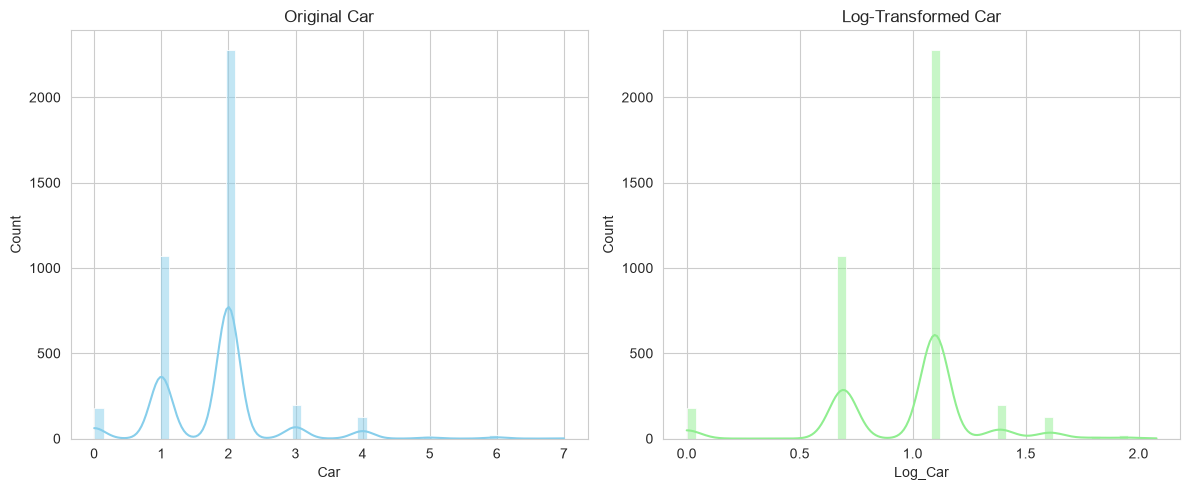

Car -> Skewness before: 1.11, after log-transform: -0.82



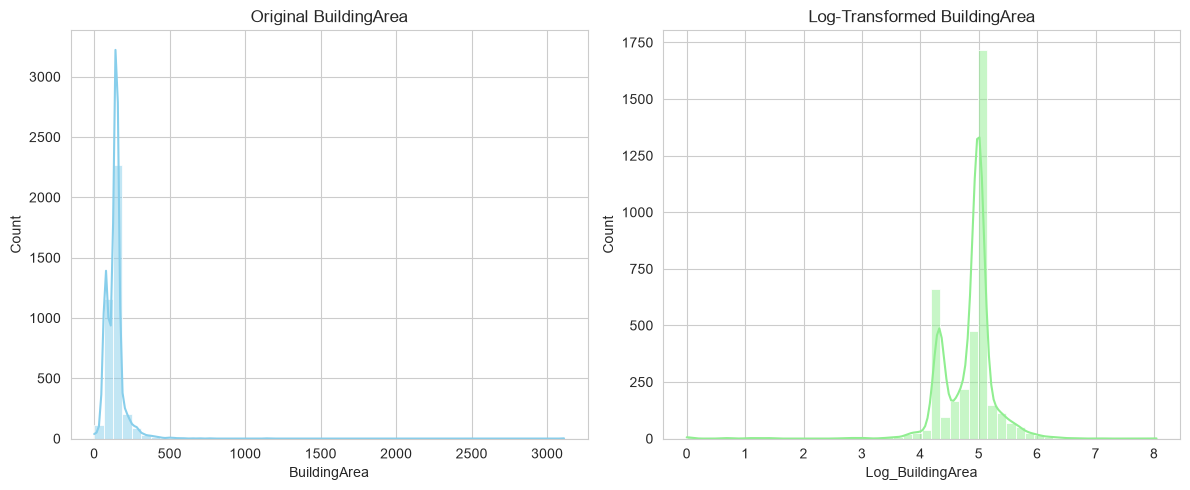

BuildingArea -> Skewness before: 16.39, after log-transform: -3.11



In [19]:
# List of columns to compare
cols_to_transform = ['Landsize', 'Distance', 'Bathroom', 'Car','BuildingArea']
# -----------------------------
# Step 1: Plot histograms
# -----------------------------
for col in cols_to_transform:
    plt.figure(figsize=(12,5))
    
    # Original
    plt.subplot(1,2,1)
    sns.histplot(sample_df[col], bins=50, kde=True, color='skyblue')
    plt.title(f'Original {col}')
    plt.xlabel(col)
    
    # Log-transformed
    plt.subplot(1,2,2)
    sns.histplot(sample_df[f'Log_{col}'], bins=50, kde=True, color='lightgreen')
    plt.title(f'Log-Transformed {col}')
    plt.xlabel(f'Log_{col}')
    
    plt.tight_layout()
    plt.show()
    
    # Print skewness before and after
    original_skew = sample_df[col].skew()
    log_skew = sample_df[f'Log_{col}'].skew()
    print(f"{col} -> Skewness before: {original_skew:.2f}, after log-transform: {log_skew:.2f}\n")

CORRELATION ANALYSIS

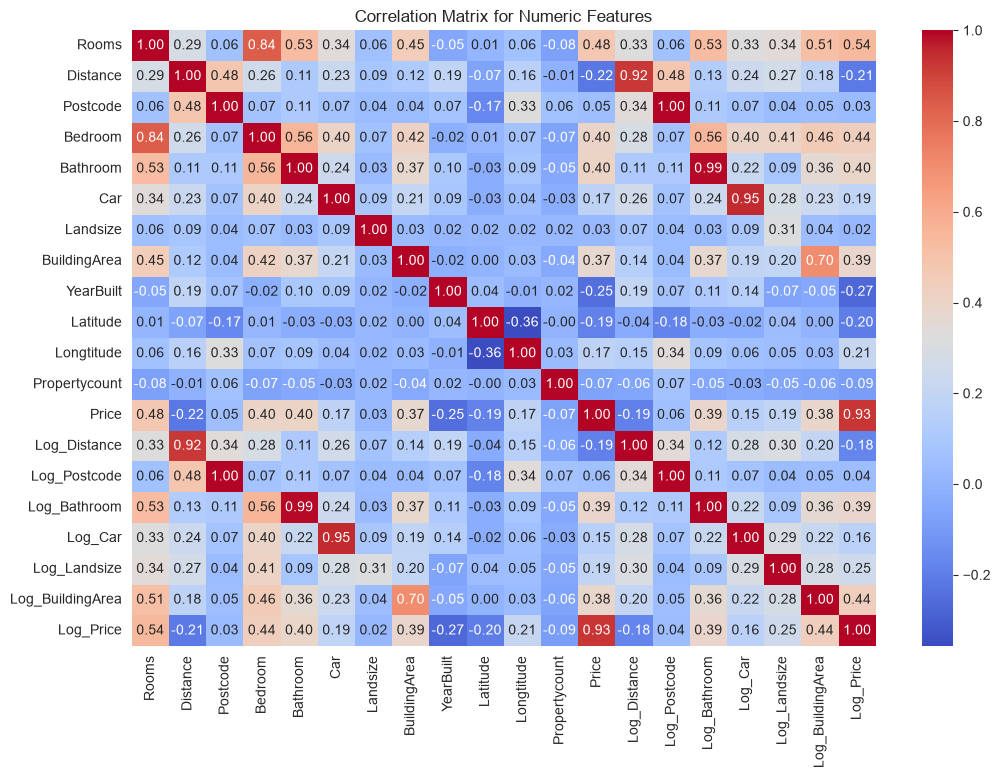

In [20]:
# Select numeric columns for correlation
numeric_cols = sample_df.select_dtypes(include='number').columns.tolist()
# Compute correlation matrix
corr_matrix = sample_df[numeric_cols].corr()

# Display correlation matrix
#print(corr_matrix)

# Optional: visualize with a heatmap
plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Correlation Matrix for Numeric Features")
plt.show()

Strong correlations between features: Rooms and Bedroom (0.83), Log_Bathroom and Bathroom (0.99), Log_Car and Car (0.95). These indicate multicollinearity, so one of each pair should be dropped or transformed for modeling.

Predictive features for price: Rooms, Bedroom, Bathroom, and log-transformed Landsize show moderate positive correlation with LogPrice (0.25–0.54).

Distance from CBD: negatively correlated with price (-0.21), meaning houses farther from the city center tend to be slightly cheaper.

Weakly correlated features: Postcode (0.03) and Propertycount (-0.07) have little linear relationship with price, so they may be less informative for regression models.

Conclusions:

Higher-income areas (proxied by Postcode) are not always more expensive; location alone does not guarantee higher prices.

Population density (proxied by Propertycount) is not strongly correlated with house value in this dataset.

Features to consider dropping: Rooms (due to high correlation with Bedroom) or Propertycount (due to low correlation with price).

This analysis informs which features to keep, transform, or drop, helping improve model performance and reduce multicollinearity.

### B. Categorical Features Analysis

In [21]:
# 1. Basic Statistics on Categorical Columns
print("\n1. BASIC STATISTICS ON CATEGORICAL COLUMNS\n")

stats_list = []
for col in categorical_cols:
    count = sample_df[col].count()
    unique = sample_df[col].nunique()
    
    stats_list.append({
        'Feature': col,
        'Total_Count': count,
        'Unique_Values': unique,
    })

stats_df = pd.DataFrame(stats_list)
print(stats_df.to_string(index=False))


1. BASIC STATISTICS ON CATEGORICAL COLUMNS

    Feature  Total_Count  Unique_Values
     Suburb         3895            295
    Address         3895           3887
       Type         3895              3
     Method         3895              5
    SellerG         3895            195
       Date         3895             77
CouncilArea         3895             32
 Regionname         3895              8
ParkingArea         3895              8


Categorical features Distribution 

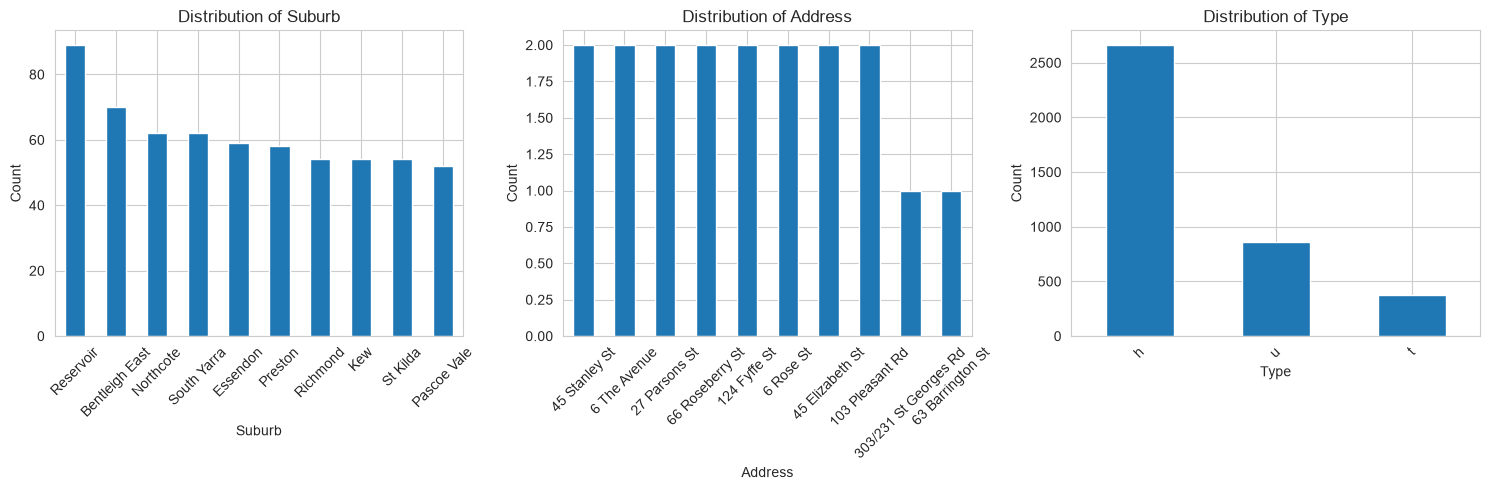

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for idx, col in enumerate(categorical_cols[:3]):
    sample_df[col].value_counts().head(10).plot(kind='bar', ax=axes[idx])
    axes[idx].set_title(f'Distribution of {col}')
    axes[idx].set_ylabel('Count')
    axes[idx].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Categorical Features vs Target

MEAN PRICE BY CATEGORY (Bar Plots)

4. MEAN PRICE BY CATEGORY (Bar Plots)


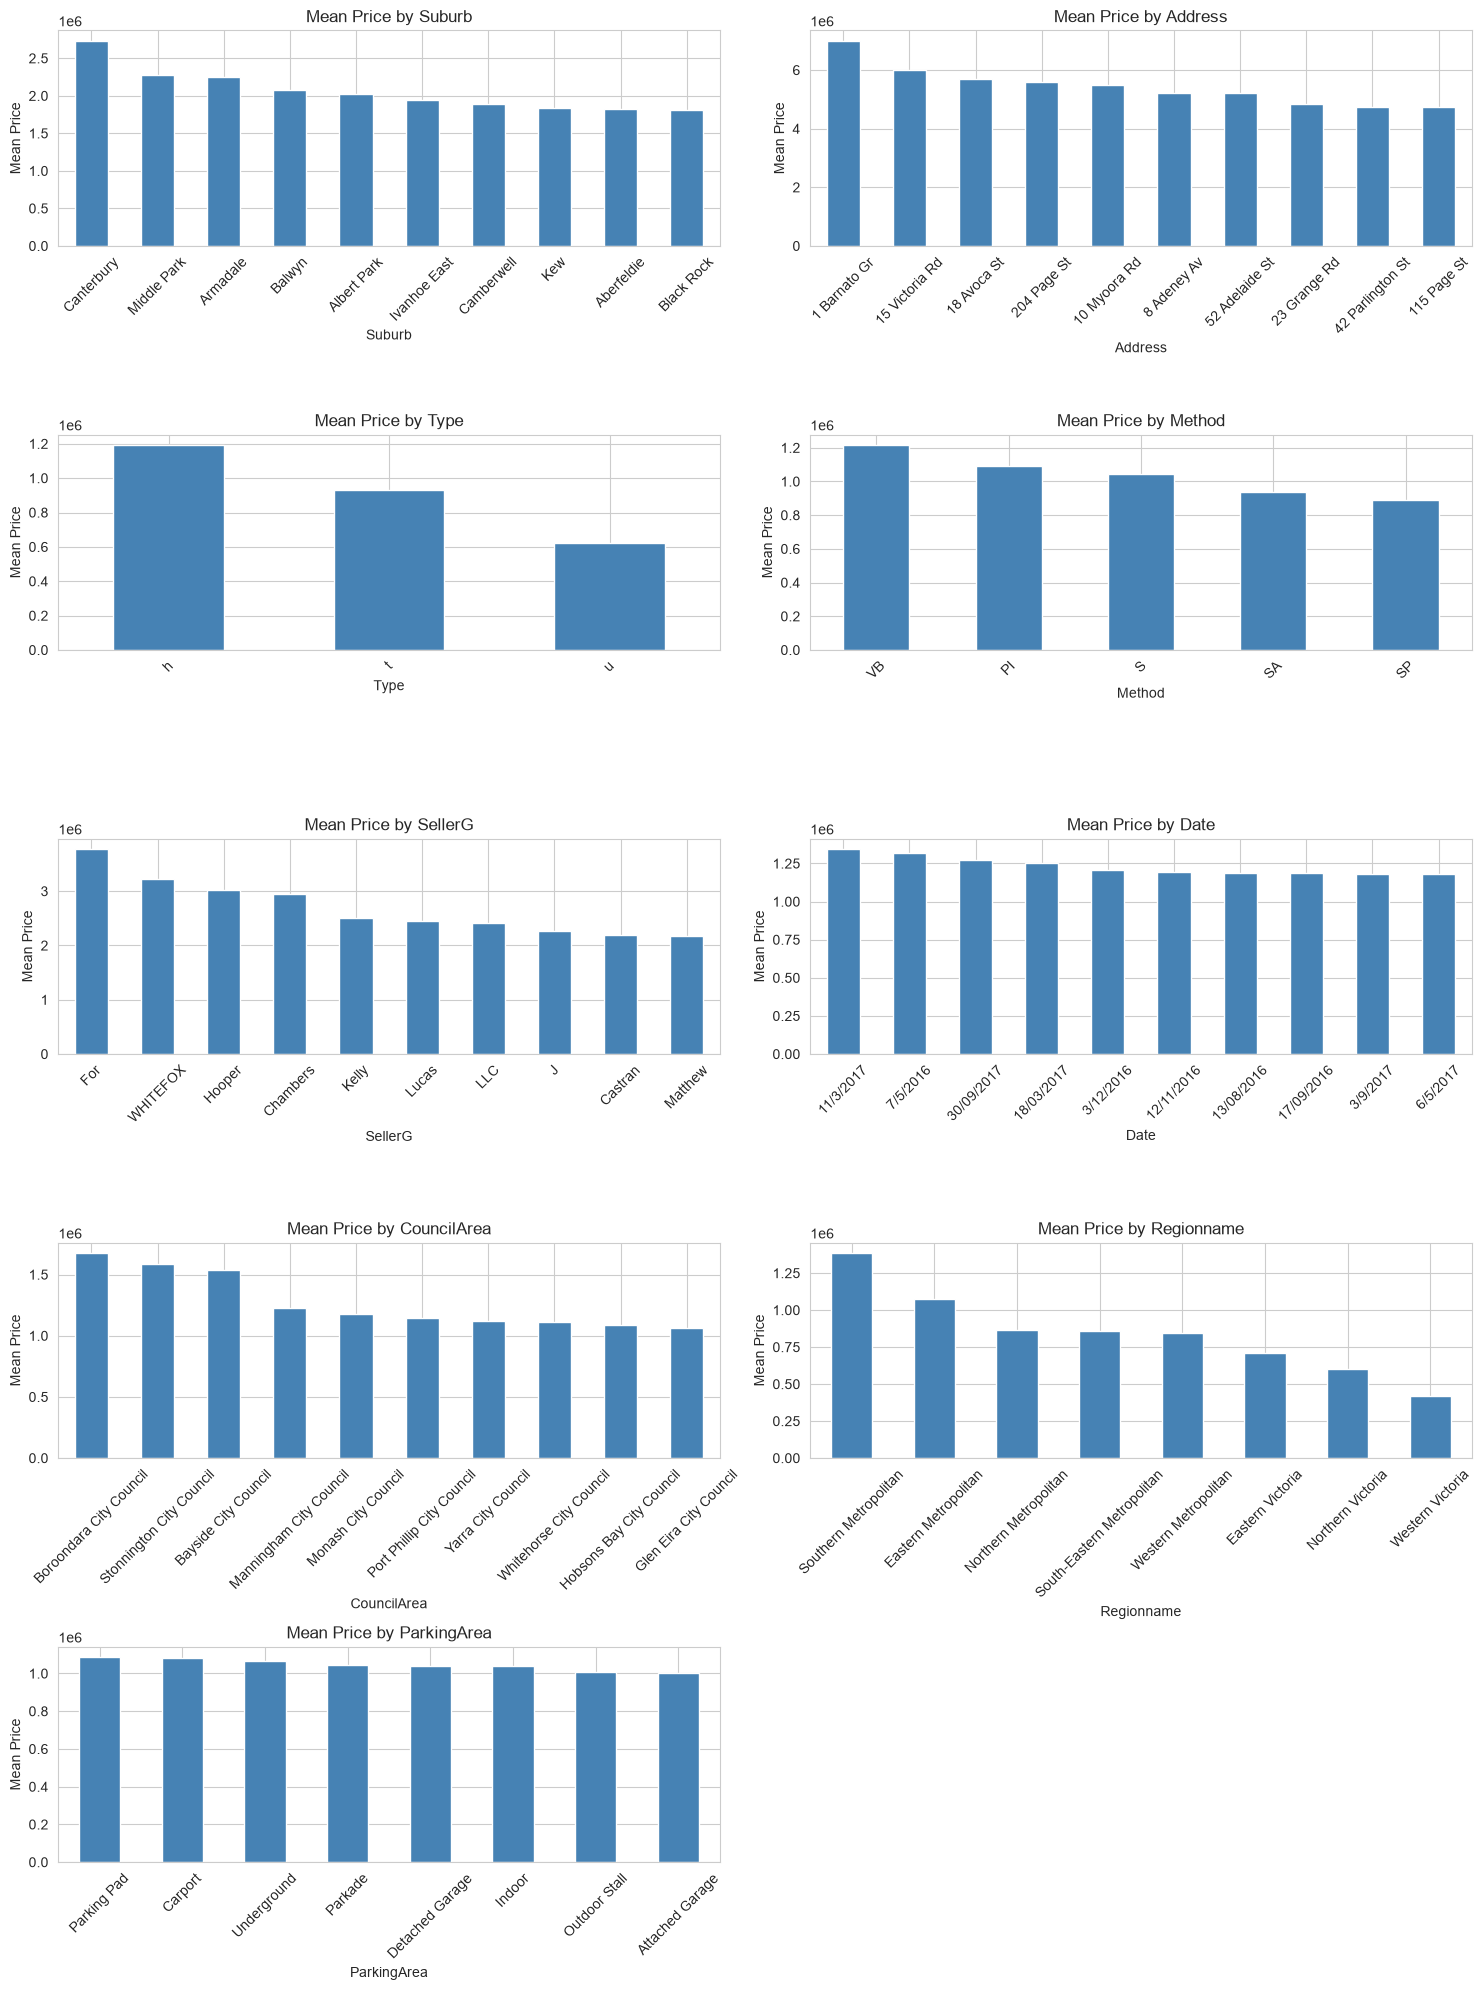

In [23]:
n_categorical = len(categorical_cols)
n_cols = 2
n_rows = (n_categorical + 1) // 2

# 4. BAR PLOTS - Mean Price per Category
print("4. MEAN PRICE BY CATEGORY (Bar Plots)")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()
for idx, col in enumerate(categorical_cols):
    mean_price = sample_df.groupby(col)['Price'].mean().sort_values(ascending=False)
    mean_price.head(n=10).plot(kind='bar', ax=axes[idx], color='steelblue')
    axes[idx].set_title(f'Mean Price by {col}')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel(f'Mean Price')
    axes[idx].tick_params(axis='x', rotation=45)

for idx in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()


> We examined categorical features against the target. Clear differences were observed:
> 
> Type: houses more expensive than townhouses, units cheapest.
> 
> Method: auction-related sales → higher prices.
> 
> CouncilArea/Regionname: inner-city & metro areas more expensive.
> 
> Conclusion: categorical variables carry predictive signal and should be kept for modeling.
> 
> Actual encoding/transformations will be handled later during feature engineering & selection.

## Target variable Analysis



In [24]:
Q1 = sample_df['Price'].quantile(0.25)
Q3 = sample_df['Price'].quantile(0.75)
IQR = abs(Q3 - Q1)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
filtered_df = sample_df[(sample_df['Price'] < lower_bound) | (sample_df['Price'] > upper_bound)]
filtered_df

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Propertycount,ParkingArea,Price,Log_Distance,Log_Postcode,Log_Bathroom,Log_Car,Log_Landsize,Log_BuildingArea,Log_Price
34238,Eaglemont,18 Carlsberg Rd,4,h,S,Miles,29/07/2017,8.9,3084.0,4.0,...,1651.0,Detached Garage,3300000.0,2.292535,8.034307,1.098612,1.386294,7.486613,5.003946,15.009433
27905,Caulfield North,127 Normanby Rd,4,h,S,Marshall,25/02/2017,8.1,3161.0,4.0,...,6923.0,Attached Garage,2625000.0,2.208274,8.058960,1.098612,1.386294,6.729824,5.003946,14.780592
34562,Yarraville,54 Pentland Pde,6,h,VB,Village,29/07/2017,6.3,3013.0,6.0,...,6543.0,Attached Garage,2450000.0,1.987874,8.011023,1.386294,1.098612,6.992096,5.964864,14.711599
30351,Fitzroy,49/183 Kerr St,3,u,S,Nelson,27/05/2017,2.1,3065.0,3.0,...,5825.0,Carport,2265000.0,1.131402,8.028129,0.693147,1.098612,6.246107,4.317488,14.633086
21069,Hawthorn East,8 Campbell Gr,5,h,S,Kay,18/11/2017,6.2,3123.0,5.0,...,6482.0,Carport,3525500.0,1.974081,8.046870,1.386294,1.098612,6.246107,6.040255,15.075533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29238,Brighton,9 Laburnum St,4,h,VB,Buxton,26/07/2016,11.2,3186.0,3.0,...,10579.0,Carport,2900000.0,2.501436,8.066835,0.693147,1.098612,6.246107,5.003946,14.880222
18195,Hawthorn East,41 Leura Gr,4,h,S,Kay,17/03/2018,6.2,3123.0,4.0,...,6482.0,Attached Garage,3575000.0,1.974081,8.046870,1.098612,1.098612,6.504288,5.739793,15.089476
20957,Essendon,20 McCarron Pde,4,h,VB,Nelson,18/11/2017,7.5,3040.0,4.0,...,9264.0,Indoor,2600000.0,2.140066,8.019942,1.386294,1.098612,6.246107,5.003946,14.771022
9682,Canterbury,29 Rubens Gr,4,h,PI,Marshall,11/2/2017,9.0,3126.0,4.0,...,3265.0,Indoor,3800000.0,2.302585,8.047829,0.693147,0.693147,6.755769,5.003946,15.150512


In [25]:
# Check the top 10 highest price outliers
filtered_df.sort_values(by='Price', ascending=False).head(10)

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Propertycount,ParkingArea,Price,Log_Distance,Log_Postcode,Log_Bathroom,Log_Car,Log_Landsize,Log_BuildingArea,Log_Price
28325,Armadale,1 Barnato Gr,4,h,PI,Kay,25/11/2017,6.3,3143.0,3.0,...,4836.0,Detached Garage,7000000.0,1.987874,8.053251,0.693147,1.098612,6.246107,5.003946,15.761421
17933,Camberwell,15 Victoria Rd,5,h,VB,Marshall,17/03/2018,7.7,3124.0,5.0,...,8920.0,Underground,6000000.0,2.163323,8.047190,1.386294,1.609438,7.199678,5.003946,15.607270
3942,South Yarra,18 Avoca St,4,h,S,Castran,12/11/2016,3.3,3141.0,4.0,...,14887.0,Detached Garage,5700000.0,1.458615,8.052615,1.098612,0.000000,5.680173,5.609472,15.555977
4955,Middle Park,204 Page St,6,h,PI,Marshall,3/6/2017,3.0,3206.0,6.0,...,2019.0,Underground,5600000.0,1.386294,8.073091,1.609438,1.098612,6.159095,5.796058,15.538277
733,Toorak,10 Myoora Rd,4,h,VB,Marshall,3/12/2016,4.6,3142.0,4.0,...,7217.0,Parkade,5500000.0,1.722767,8.052933,1.386294,1.098612,6.539586,5.926926,15.520259
4061,Armadale,52 Adelaide St,5,h,SP,Marshall,1/7/2017,6.3,3143.0,5.0,...,4836.0,Attached Garage,5200000.0,1.987874,8.053251,1.386294,1.386294,6.635947,5.003946,15.464169
9235,Kew,8 Adeney Av,6,h,VB,Marshall,9/12/2017,5.4,3101.0,6.0,...,10331.0,Detached Garage,5200000.0,1.856298,8.039802,1.098612,1.098612,7.404279,6.006353,15.464169
3820,Kew,23 Grange Rd,5,h,S,Caine,12/11/2016,5.6,3101.0,5.0,...,10331.0,Detached Garage,4850000.0,1.887070,8.039802,1.609438,1.609438,6.864848,5.993961,15.394489
30208,Canterbury,42 Parlington St,4,h,S,Kay,27/05/2017,8.4,3126.0,4.0,...,3265.0,Indoor,4750000.0,2.240710,8.047829,1.386294,1.098612,6.875232,6.154858,15.373655
27757,Albert Park,115 Page St,4,h,S,Marshall,25/02/2017,3.3,3206.0,4.0,...,3280.0,Carport,4735000.0,1.458615,8.073091,1.098612,0.693147,5.802118,5.337538,15.370492


In [26]:
# Check the top 10 lowest price outliers
filtered_df.sort_values(by='Price', ascending=True).head(10)


,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Propertycount,ParkingArea,Price,Log_Distance,Log_Postcode,Log_Bathroom,Log_Car,Log_Landsize,Log_BuildingArea,Log_Price
1791,South Melbourne,352 Moray St,4,h,PI,Marshall,7/5/2016,2.1,3205.0,5.0,...,5943.0,Indoor,2260000.0,1.131402,8.072779,1.386294,0.000000,5.252273,5.451038,14.630876
512,Glen Iris,28 Malvern Av,3,h,S,J,3/12/2016,9.2,3146.0,3.0,...,10412.0,Parkade,2260000.0,2.322388,8.054205,0.693147,1.098612,6.246107,5.003946,14.630876
23006,Beaumaris,37 Deauville St,4,h,S,Marshall,21/10/2017,17.3,3193.0,4.0,...,5366.0,Outdoor Stall,2260000.0,2.906901,8.069029,1.098612,1.098612,6.246107,5.602119,14.630876
30351,Fitzroy,49/183 Kerr St,3,u,S,Nelson,27/05/2017,2.1,3065.0,3.0,...,5825.0,Carport,2265000.0,1.131402,8.028129,0.693147,1.098612,6.246107,4.317488,14.633086
23542,Surrey Hills,14 Grovedale Rd,4,h,S,Lindellas,21/10/2017,10.2,3127.0,4.0,...,5457.0,Outdoor Stall,2285000.0,2.415914,8.048149,1.098612,1.098612,6.442540,5.707110,14.641877
33573,South Yarra,90 River St,3,h,SP,Marshall,28/10/2017,2.7,3141.0,3.0,...,14887.0,Outdoor Stall,2300000.0,1.308333,8.052615,1.098612,1.098612,5.356586,5.003946,14.648420
25697,South Yarra,203/8 Murphy St,3,u,VB,Kay,23/09/2017,2.7,3141.0,3.0,...,14887.0,Carport,2300000.0,1.308333,8.052615,0.693147,1.098612,6.246107,4.317488,14.648420
34673,Malvern,31a Winter St,3,h,S,Jellis,30/07/2016,7.4,3144.0,3.0,...,4675.0,Indoor,2300000.0,2.128232,8.053569,1.098612,1.098612,5.749393,5.003946,14.648420
23430,Port Melbourne,273 Ross St,4,h,S,Marshall,21/10/2017,3.5,3207.0,4.0,...,8648.0,Detached Garage,2300000.0,1.504077,8.073403,1.386294,0.693147,6.246107,5.225747,14.648420
27653,South Melbourne,372 Dorcas St,3,h,S,RT,24/09/2016,2.1,3205.0,3.0,...,5943.0,Indoor,2300000.0,1.131402,8.072779,1.098612,1.098612,0.000000,5.564520,14.648420


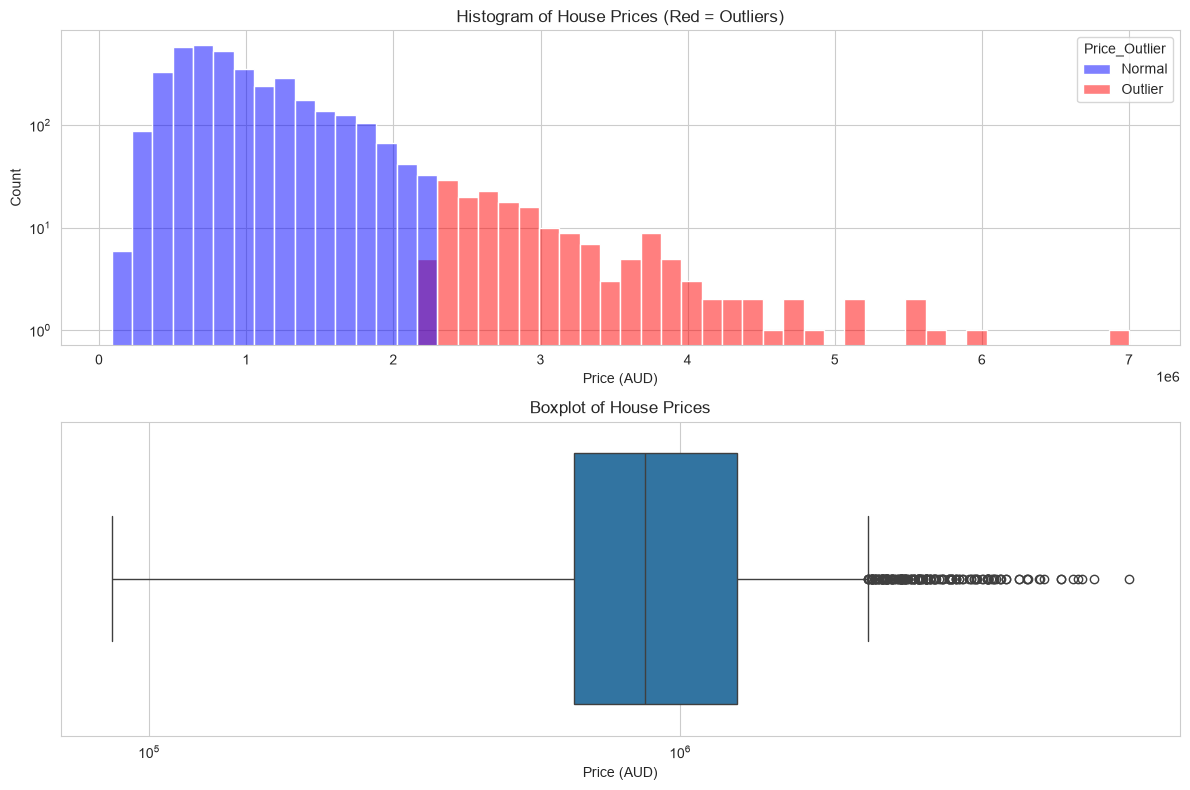

Rooms                0.295477
Distance             1.460687
Postcode             3.933717
Bedroom              0.297706
Bathroom             1.537199
Car                  1.111266
Landsize            27.881094
BuildingArea        16.387664
YearBuilt           -0.534291
Latitude            -0.285021
Longtitude          -0.356991
Propertycount        0.915845
Price                2.416740
Log_Distance        -0.383174
Log_Postcode         3.516681
Log_Bathroom         0.949147
Log_Car             -0.817864
Log_Landsize        -2.747708
Log_BuildingArea    -3.105498
Log_Price            0.329148
dtype: float64


In [27]:
# Flag rows as outlier or not
sample_df['Price_Outlier'] = sample_df['Price'].apply(
    lambda x: 'Outlier' if x < lower_bound or x > upper_bound else 'Normal'
)
# Create figure with two subplots
fig, axs = plt.subplots(2, 1, figsize=(12, 8))

# Histogram
sns.histplot(data=sample_df, x='Price', hue='Price_Outlier', palette={'Normal':'blue','Outlier':'red'}, bins=50, ax=axs[0])
axs[0].set_title('Histogram of House Prices (Red = Outliers)')
axs[0].set_xlabel('Price (AUD)')
axs[0].set_ylabel('Count')
axs[0].set_yscale('log')  # optional, to better visualize high counts

# Boxplot
sns.boxplot(data=sample_df, x='Price', ax=axs[1])
axs[1].set_title('Boxplot of House Prices')
axs[1].set_xlabel('Price (AUD)')
axs[1].set_xscale('log')  # optional, handles extreme high values

plt.tight_layout()
plt.show()

# Skewness of numeric columns
print(sample_df.skew(numeric_only=True))


> The Price column is highly positively skewed due to a few very expensive houses. To reduce skewness and stabilize variance, I applied a log transformation to Price. This compresses extreme high values, spreads out smaller values, and makes the data distribution more suitable for modeling and analysis

In [28]:
# Create a new column for log-transformed price
sample_df['LogPrice'] = np.log(sample_df['Price'])

# Check the skewness after transformation
print("Skewness of original Price:", sample_df['Price'].skew())
print("Skewness of log-transformed Price:", sample_df['LogPrice'].skew())


Skewness of original Price: 2.416740465803807
Skewness of log-transformed Price: 0.3291462410340791


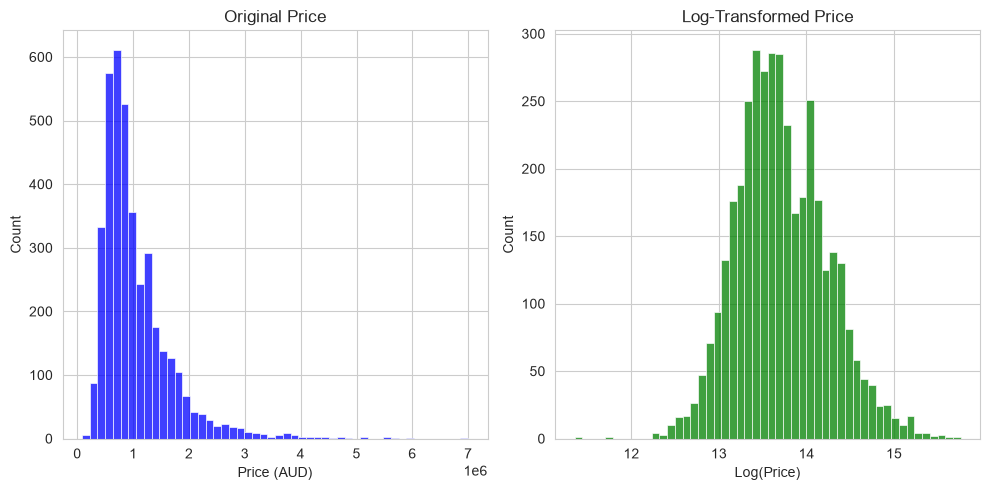

In [29]:
plt.figure(figsize=(10,5))

# Histogram of original Price
plt.subplot(1,2,1)
sns.histplot(sample_df['Price'], bins=50, color='blue')
plt.title('Original Price')
plt.xlabel('Price (AUD)')

# Histogram of log-transformed Price
plt.subplot(1,2,2)
sns.histplot(sample_df['LogPrice'], bins=50, color='green')
plt.title('Log-Transformed Price')
plt.xlabel('Log(Price)')

plt.tight_layout()
plt.show()